# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
plans.head(5)
#plans.shape

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean().sort_values(ascending=False))

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
churn_date    0.88350
city          0.11725
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
reg_date      0.00000
plan          0.00000
dtype: float64


In [11]:

print(usage.isna().sum())
print(usage.isna().mean().sort_values(ascending=False))


id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
duration    0.55190
length      0.44740
date        0.00125
id          0.00000
user_id     0.00000
type        0.00000
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
  En el caso del Dataframe: Users. Dos columnas tienen nulos que son: churn_date** y city**. Churn_date cuenta con 88% de datos nulos es por esto que se toma la decisión que se ignora la columna. Por otro lado, city cuenta con un 11% de nulos los cuales se van a investigar.
  En el caso del Dataframe: Usage. Tres columnas tienen nulos, las cuales son: date**, duration** y length**. Duration con un porcentaje de 55% y length de 44%. Se decide investigar e imputar porque son columnas importantes y además tienen menos del 80%. 
- Indica qué harías: ¿imputar, eliminar, ignorar?

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
columnas_user=['age','user_id']
users[columnas_user].describe()



,age,user_id
count,4000.000000,4000.000000
mean,33.739750,11999.500000
std,123.232257,1154.844867
min,-999.000000,10000.000000
25%,32.000000,10999.750000
50%,47.000000,11999.500000
75%,63.000000,12999.250000
max,79.000000,13999.000000


-Se analizan dos columnas numericas. La primera es "user_id" que es de tipo numerico como identificador y "age" de tipo numerico y que corresponde a la edad de los usuarios. La columna 'age' presenta un sentinel en el valor min con -999, un valor que no es valido para una categoría como edad. 


In [13]:
columnas_usage=['id','user_id']
usage[columnas_usage].describe()


,id,user_id
count,40000.00000,40000.000000
mean,20000.50000,12002.405975
std,11547.14972,1157.279564
min,1.00000,10000.000000
25%,10000.75000,10996.000000
50%,20000.50000,12013.000000
75%,30000.25000,13005.000000
max,40000.00000,13999.000000


- Las columnas `id` y `user_id'  son de tipo numerico pero representan una identificación del usuario. Podemos observar que hay más valores de id que de user_id seria importante definir cual de las dos se va a usar para identificar el usuario. 

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
print(users[columnas_user].value_counts())
print(users["city"].unique())
print(users["plan"].unique())


city      plan   
Bogotá    Basico     522
CDMX      Basico     474
Medellín  Basico     398
GDL       Basico     298
Bogotá    Premium    286
MTY       Basico     275
Cali      Basico     262
CDMX      Premium    256
Medellín  Premium    218
Cali      Premium    162
GDL       Premium    152
MTY       Premium    132
?         Basico      65
          Premium     31
dtype: int64
['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']
['Basico' 'Premium']


-Se analizan las columnas categoricas relevantes del dataframe: USERS y se hallan los valores unicos. En el caso de la columna 'plan' encontramos dos tipos de plan Basico y Premium a simple vista no se ve que existe algun error de sintaxis. Por otro lado, la columna 'city' presenta 7 categorias distintas, escritas de diferente forma que se deben corregir y aparece un sentinel '?' lo que puede indicar una columna que no está definida y que debe ser revisada. 

In [15]:
# explorar columna categórica de usage
print(usage['type'].value_counts())
print(usage['type'].unique())


text    22092
call    17908
Name: type, dtype: int64
['call' 'text']


- La columna `type` corresponde a una columna categórica del dataframe: USAGE. En este caso, encontramos dos tipos en la columna 'Type' los cuales son text y call. No existen errores en la sintaxis o categorias iguales escritas en diferentes formas.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  Se encontró un valor inválido en la columna 'age' del dataframe USERS que corresponde a un valor de -999. Es un valor que se considera inválido para esta categoria por lo cual se debe corregir. Por otro lado, en la columna categorica 'city' en el dataframe USERS encontramos que se debe estandarizar el texto porque algunas ciudades se nombran con las siglas. De igual manera, se encuentra un sentinel "?" en esta columna que puede ser porque una ciudad no se identifico. 
- ¿Qué acción tomarías? Se puede considerar reemplazar el sentinel '-999' con la mediana o mediana dependiendo al comportamiento de los datos. Reemplazar los sentinels como valores nulos y estandarizar el texto en la columna 'city'.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users["reg_date"],errors="coerce")


In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage["date"],errors="coerce")


In [18]:
users["reg_date"].dt.year.value_counts()


2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

En `reg_date` existen valores desde el año 2024 hasta el 2026. No existen datos por fuera de este rango.

In [19]:
usage['date'].dt.year.value_counts()

2024.0    39950
Name: date, dtype: int64

En 'date' existen solo valores disponibles para el año 2024 con una cantidad de 39950.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos) No aparecen años viejos o sin transcurrir al momento de guardar los datos. Sin embargo, el dataframe USERS presenta datos desde el 2024 hasta el 2026 y el dataframe USAGE solo presenta datos del 2024. 
- ¿Qué harías con ellas? Seria importante decidir si solo se va a tener en cuenta el año 2024 debido a que es el año que aparece en los dos dataframes analizados.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users["age"].median()
users['age']=users['age'].replace([-999],np.nan)
users['age'] = users["age"].fillna(users["age"].median())

# Verificar cambios
users['age'].describe()
#users['age'].isna().sum()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:

users['city']=users['city'].replace(["?"],pd.NA)
users['city'].isna().sum()


565

In [22]:
(users['reg_date']>pd.Timestamp.now()).sum()


0

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
print(usage[usage['duration'].isna()]['type'].value_counts(normalize=True))
print(usage[usage['duration'].notna()]['type'].value_counts(normalize=True))


text    1.0
Name: type, dtype: float64
call    0.999107
text    0.000893
Name: type, dtype: float64


In [24]:
# Verificación MAR en usage (Missing At Random) para length
print(usage[usage['length'].isna()]['type'].value_counts(normalize=True))
print(usage[usage['length'].notna()]['type'].value_counts(normalize=True))


call    1.0
Name: type, dtype: float64
text    0.999457
call    0.000543
Name: type, dtype: float64


Se encontró la relación entre la columna 'duration' y 'length' con la columna 'type' que representa el tipo si es call o text. En el caso de la columna 'duration' el 100% de los valores nulos son text y tiene sentido porque un mensaje no tiene duración para calcular. Por otro lado, en el caso de 'length' el 100% de los valores nulos son de tipo call y tiene sentido porque no se puede calcular la longitud a una llamada. Es por esto, que en el contexto del negocio tiene sentido dejarlos como nulos.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id')[['is_text','is_call','duration']].sum().reset_index()


# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Renombrar columnas

usage_agg = usage_agg.rename(columns={"is_text":"cant_mensajes","is_call":"cant_llamadas","duration":"cant_minutos_llamada"})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(users,usage_agg, on="user_id", how="left")
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas

columnas_usage = print(usage[['duration','length']].describe())
print(users["age"].describe())

           duration        length
count  17924.000000  22104.000000
mean       5.202237     52.127398
std        6.842701     56.611183
min        0.000000      0.000000
25%        1.437500     37.000000
50%        3.500000     50.000000
75%        6.990000     64.000000
max      120.000000   1490.000000
count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64


In [29]:
# Distribución porcentual del tipo de plan
users['plan'].value_counts(normalize=True)*100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

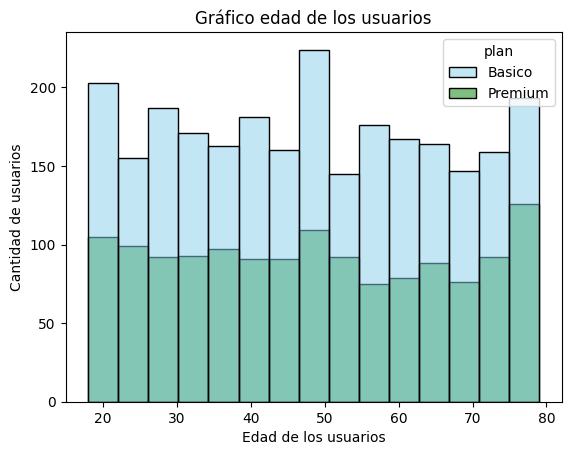

In [30]:
# Histograma para visualizar la edad (age)
sns.histplot(data=users, x='age', hue='plan', bins=15, palette=['skyblue','green'])
plt.xlabel('Edad de los usuarios')
plt.ylabel('Cantidad de usuarios')
plt.title('Gráfico edad de los usuarios')
plt.show()

💡Insights: 
- El histograma presenta una distribución sesgada a la derecha lo que quiere decir que la mayoría de los usuarios estan entre una edad de 20 a 50 años. Dentro del plan Premium hay mayor proporción de clientes entre los 75 y 80 años. Por otro lado, el plan basico presenta mayor proporción en las personas entre 45 y 50 años. 

Text(0.5, 1.0, 'Gráfico cantidad de mensajes')

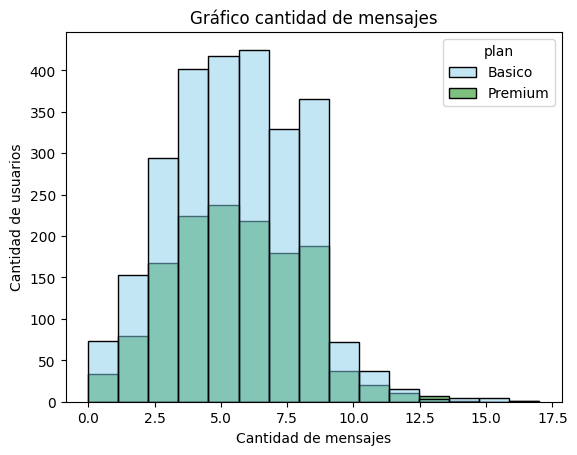

In [31]:
# Histograma para visualizar la cant_mensajes

sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', bins=15, palette= ['skyblue','green'])
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.title('Gráfico cantidad de mensajes')


💡Insights: 
- El histograma muestra una distribución sesgada a la derecha. Las personas que usan el plan Premium tienen una mayor cantidad de mensajes. Por otro lado, también se puede observar que hay una mayor proporción de usuarios que usan el plan Basico en comparación a las personas que usan el Premium. 

Text(0.5, 1.0, 'Gráfico cantidad de llamadas')

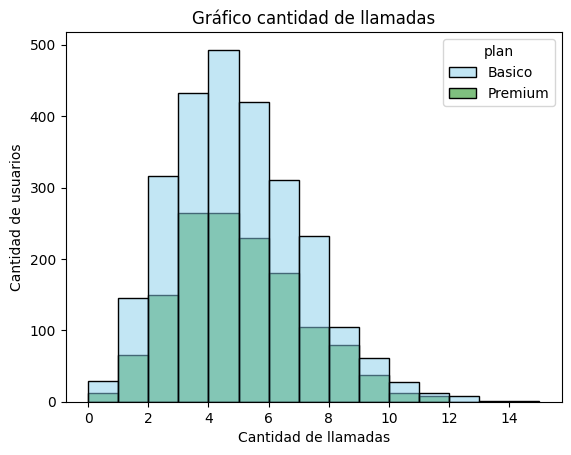

In [32]:
# Histograma para visualizar la cant_llamadas

sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', bins=15, palette= ['skyblue','green'])
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.title('Gráfico cantidad de llamadas')



💡Insights: 
- El gráfico presenta una distribución sesgada a la derecha. Las usuarios del plan Basico y Premium realizan en mayor proporción entre 2 a 8 llamadas. La cantidad de llamadas predominante para los usuarios Basicos es entre 4 a 5 llamadas. Por otro lado, los usuarios Premium predominan realizando entre 3 a 5 llamadas.

Text(0.5, 1.0, 'Gráfico de minutos x llamada')

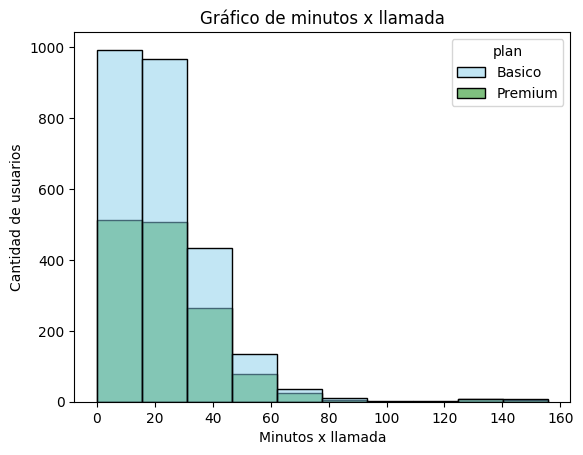

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', bins=10, palette= ['skyblue','green'])
plt.xlabel('Minutos x llamada')
plt.ylabel('Cantidad de usuarios')
plt.title('Gráfico de minutos x llamada')


💡Insights: 
- Distribución sesgada a la derecha porque la mayoría de datos están hacia el lado izquierdo. Podemos observar que existen algunos datos atipicos que hay que revisar, algunos usuarios que hicieron llamadas de 130 a 150 min aproximadamente. La mayoría de lo usuarios realizan llamadas entre 0 a 30 min. 

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

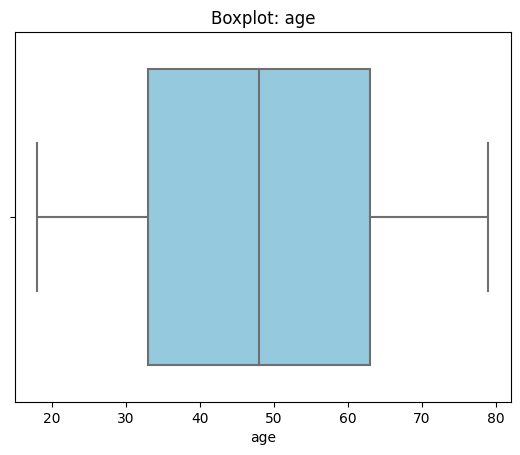

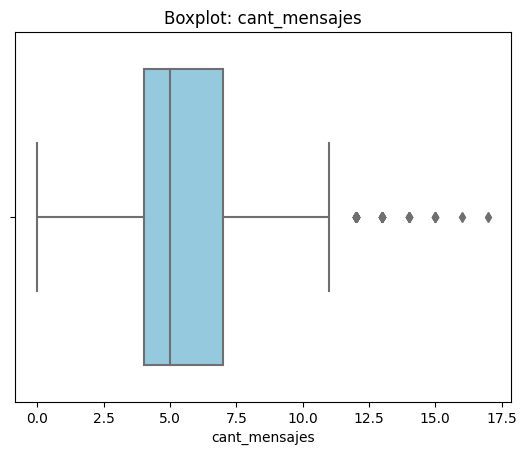

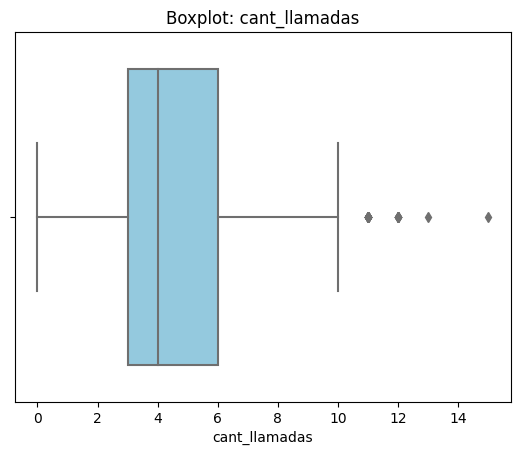

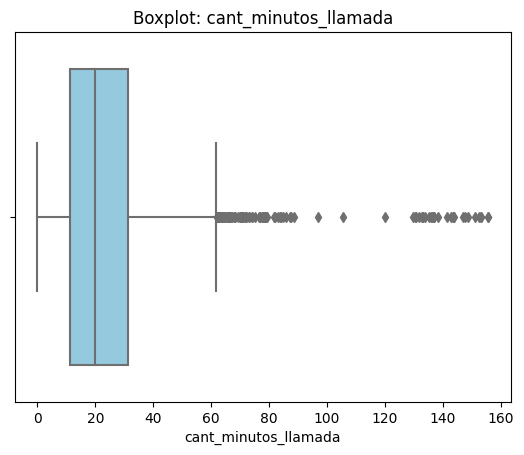

In [34]:

columnas_numericas = ['age','cant_mensajes','cant_llamadas','cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(x=user_profile[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights: 
- Age: Según el boxplot, podemos observar que no se encuentran outliers. La caja es grande lo que puede indicar que hay dispersión en los datos. Sin embargo, la limpieza y correción de los datos hecha anterior mente funcionó y no hay datos fuera de los limites. 
- cant_mensajes: Según el boxplot, encontramos 6 valores considerados como outliers. El gráfico presenta sesgo a la derecha y sería necesario utilizar el metodo IQR. 
- cant_llamadas: Según el boxplot, encontramos 4 valores considerados como outliers. El gráfico presenta sesgo a la derecha y la media se acerca más el primer cuartil Q1.
- cant_minutos_llamada: Según el boxplot, existen muchos valores atipicos y el sesgo a la derecha es mas notorio en comparación a los otros gráficos. Se necesita usar el método IQR.

In [35]:


# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes','cant_llamadas','cant_minutos_llamada']

for col in columnas_limites:
    Q1= user_profile[col].quantile(0.25)
    Q3=user_profile[col].quantile(0.75)
    IQR = Q3-Q1
    limite_superior = Q3 + 1.5*IQR
    outliers = user_profile [ user_profile[col] > limite_superior]
    print(col, len(outliers))
 

cant_mensajes 46
cant_llamadas 30
cant_minutos_llamada 109


In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué? En la columna 'cant_mensajes' podemos observar que el limite superior con el metodo IQR es de 46 y el max es de 17. 
- cant_llamadas: mantener o no outliers, porqué? En la columna 'cant_llamadas' podemos observar que el limite superior con el metodo IQR es de 30 y el max es de 15. 
- cant_minutos_llamada: mantener o no outliers, porqué? En la columna 'cant_minutos_llamada' podemos observar que el limite superior con el método IQR es de 109 y el max es de 155.

Se decide dejar los outliers en estas tres columnas porque son valores de uso real, no errores de medición y eliminarlos provocaría que se pierda información valida del comportamiento de los clientes. 

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:

# Crear columna grupo_uso

def clasificar_clientes(row):
    llamadas = row['cant_llamadas']
    mensajes = row['cant_mensajes']
    
    if llamadas < 5 and mensajes <5:
         return 'Bajo uso'
    elif llamadas < 10 and mensajes < 10:
         return 'Uso medio'
    else: 
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificar_clientes, axis=1)



In [38]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:

# Crear columna grupo_edad
def clasificar_edad(age):
    if age < 30:
        return 'Joven'
    elif age < 60:
        return 'Adulto'
    else: 
        return 'Adulto mayor'

user_profile['grupo_edad'] = user_profile['age'].apply(clasificar_edad)

    


In [45]:
# verificar cambios
user_profile.head()

pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'], normalize="index") * 100

pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'])

segmento_valioso= user_profile[(user_profile['grupo_edad'] =='Joven') & (user_profile['grupo_uso']== 'Uso medio')]

segmento_valioso['plan'].value_counts()

Basico     352
Premium    200
Name: plan, dtype: int64

### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

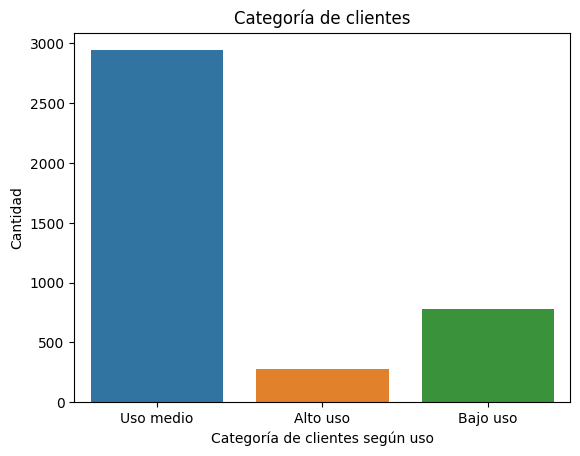

In [41]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso')
plt.title('Categoría de clientes')
plt.xlabel('Categoría de clientes según uso')
plt.ylabel('Cantidad')
plt.show()

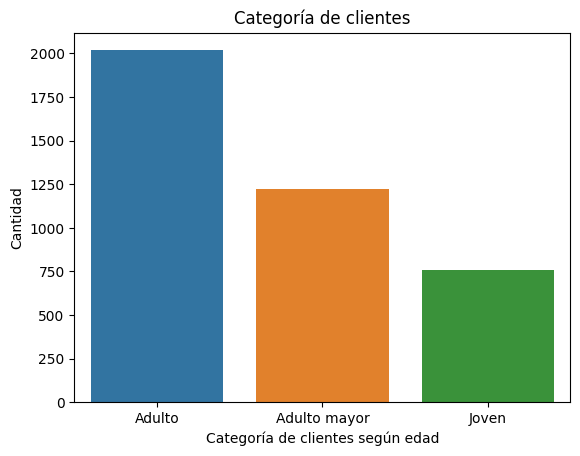

In [42]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad')
plt.title('Categoría de clientes')
plt.xlabel('Categoría de clientes según edad')
plt.ylabel('Cantidad')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

El proyecto 6 tiene como objetivo el análisis de una empresa de telecomunicaciones y responder las preguntas de negocio teniendo en cuenta tres fuentes de datos. El primer paso constaba en explorar los dataframes. En este punto, nos dimos cuenta que el dataset 'Plans' solo contaba con 2 filas y 8 columnas. Es por ello, que la mayoría del analisis y la limpieza se realizo con los dos datasets que presentaban más datos disponibles. 
El segundo paso fue identificar los problemas de calidad como nulos, sentinels o fechas fuera de rango. 

- En el caso del dataframe 'Users' se encontraron nulos en las columnas como: 'City' y 'Churn_date' con un porcentaje de representación de 11% y 88% respectivamente. En el caso de la columna que presenta un porcentaje mayor del 80% se decide no tenerlo en cuenta para la limpieza. Sin embargo, el 11% en una columna como 'City' puede representar que existen inconsistencias en la manera como están escritas las ciudades y que se debe corregir.

Por otro lado, con respecto a los valores llamados 'Sentinels' en la columna 'Age' se encuentra un valor de -999 el cual no tiene sentido por la categoría de la columna y en la columna 'City' se encuentra un valor de ? que puede afectar el analisis y debe ser corregido. 

-En el caso del dataframe 'Usage' se encuentraron nulos en las columnas como: 'Date', 'Duration', 'Length' con un porcentaje de representación de menos del 1%, 55% y 44% respectivamente. En este caso son valores numericos y seria importante identificar si esos valores nulos dependen de alguna otra columna. 


🔍 **Segmentos por Edad**

Por edad identificamos tres segmentos diferentes de clientes: Adulto, adulto mayor y Joven. Se realizo un análisis con la función .crosstab para saber el porcentaje de uso para cada categoría de clientes. Las tres categorías presentan una mayor participación en 'Uso medio' con más del 70%. La categoría con mayor porcentaje en 'Alto uso' fueron los adultos con un 7.63% y en 'Bajo uso' fue el adulto mayor con un 21%. 

📊 **Segmentos por Nivel de Uso**
Por uso identificamos tres segmentos diferentes: Alto uso, Bajo uso y Uso medio. La mayoría de los clientes estan concentrados en el consumo de 'Uso medio'. La combinación de edad= 'Adulto' y Uso= 'Uso medio' presenta el mayor porcentaje con un 74.33% que corresponde a 1500 personas de las cuales 977 consumen el plan basico y 523 el plan premium. Se analizaron también varias combinaciones de grupos de edad y según el nivel de uso, y todos tienen en comun el uso del plan Basico, esto podría ser porque el valor del plan premium es elevado y no es igual de accesible a las personas. 


➡️ Esto sugiere que: 

-Los adultos son la mayor proporción de los clientes. En este caso, para aprovechar el nicho y aumentar el consumo de esta categoría, sugeriría planes de consumo que puedan beneficiarlos. Como por ejemplo: plan de llamadas internacionales, la mayoría puede usarlo para comunicarse con sus familiares que están lejos. 

-Por otro lado, otra proporción de clientes que vale la pena analizar es la de 'Jovenes'. La combinación de 'Jovenes' con 'Uso medio' tiene una proporción de 64% usan el plan basico y 36% usan el plan premium. Se sugiere desarollar una idea de plan que pueda atraerlos a aumentar el uso. Por ejemplo: los jovenes no solo buscan un plan con llamadas y mensajes, una idea atractiva puede ser un plan que además contenga alguna aplicación de streaming o un beneficio adicional. 


💡 **Recomendaciones**
- Una de las recomendaciones seria realizar un analisis de los precios de cada uno de los planes con el comportamiento del cliente para poder saber cuál es el potencial de ingresos. Poder reeplantearse los precios y hacerlos más accesible a las personas que más consumen el producto puede provocar un aumento de las ventas y el rendimiento de ganancia. 
- Se encontraron outliers en columnas como 'cant_llamadas','cant_mensajes' y 'cant_min_llamadas' y se decidio que se manterian esos datos porque mostraban el comportamiento real de los clientes. En este caso, se puede implementar un reward por la fidelización de los clientes o un plan especial para incentivarlos a aumentar su consumo.


---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`